In [1]:
import pandas as pd
import ccf_streamlines.morphology as ccfmorph
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

import numpy as np
import json
import seaborn as sns
import umap

In [2]:
def basic_morph_df_plot(morph, ax, x_ind=0, y_ind=1, alpha=1.0, scale_factor=10.0, zorder=1, x_offset=0, color="black"):
    lines_x = []
    lines_y = []
    morph_vals = morph.values
    for i in range(morph_vals.shape[0]):
        parent_id = morph_vals[i, 6]
        if parent_id == -1:
            continue
        p_ind = np.flatnonzero(morph_vals[:, 0] == parent_id)[0]
        lines_x += [morph_vals[p_ind, x_ind + 2] / scale_factor + x_offset, morph_vals[i, x_ind + 2] / scale_factor + x_offset, None]
        lines_y += [morph_vals[p_ind, y_ind + 2] / scale_factor, morph_vals[i, y_ind + 2] / scale_factor, None]
    ax.plot(lines_x, lines_y, linewidth=0.25, alpha=alpha, zorder=zorder, color=color)
    return ax


In [3]:
def compartment_morph_df_plot(morph, ax, x_ind=0, y_ind=1, alpha=1.0, scale_factor=10.0, zorder=1, x_offset=0,
                              compartment_colors={3: "black", 4: "black"}):
    all_morph_vals = morph.values
    for c_type, color in compartment_colors.items():
        lines_x = []
        lines_y = []
        c_type_mask = all_morph_vals[:, 1] == c_type
        morph_vals = all_morph_vals[c_type_mask, :]
        for i in range(morph_vals.shape[0]):
            parent_id = morph_vals[i, 6]
            if parent_id == -1:
                continue
            p_ind = np.flatnonzero(all_morph_vals[:, 0] == parent_id)[0]
            lines_x += [all_morph_vals[p_ind, x_ind + 2] / scale_factor + x_offset, morph_vals[i, x_ind + 2] / scale_factor + x_offset, None]
            lines_y += [all_morph_vals[p_ind, y_ind + 2] / scale_factor, morph_vals[i, y_ind + 2] / scale_factor, None]
        ax.plot(lines_x, lines_y, linewidth=0.25, alpha=alpha, zorder=zorder, color=color)
    return ax


In [4]:
def adjust_lightness(color, amount=0.5):
    import matplotlib.colors as mc
    import colorsys
    try:
        c = mc.cnames[color]
    except:
        c = color
    c = colorsys.rgb_to_hls(*mc.to_rgb(c))
    return colorsys.hls_to_rgb(c[0], max(0, min(1, amount * c[1])), c[2])


In [5]:
anno_df = pd.read_feather("/allen/programs/celltypes/workgroups/rnaseqanalysis/shiny/patch_seq/star/archived/mouse_patchseq_VISp_20210818_collapsed40_cpm/anno.feather")

In [6]:
anno_df["spec_id_label"] = pd.to_numeric(anno_df["spec_id_label"])

In [7]:
color_dict = dict(zip(anno_df["cluster_label"], anno_df["cluster_color"]))

In [8]:
me_types = pd.read_csv("../../me_clust_output/exc_met_mouse_me_clustering_Jan2025/refined_text_labels.csv", index_col=0)
# me_types = pd.read_csv("../../me_clust_output/exc_met_mouse_me_clustering_Jan2025/elmo_clust_labels.csv", index_col=0)
unrefined_me_types = pd.read_csv("../../me_clust_output/exc_met_mouse_me_clustering_Jan2025/elmo_clust_labels.csv", index_col=0)
# me_types = pd.read_csv("../../me_clust_output/exc_met_mouse_me_clustering_Jan2025/elmo_clust_labels.csv", index_col=0)

In [9]:
ephys_df = pd.read_csv("/allen/programs/celltypes/workgroups/ivscc/nathang/spca_output/sparse_pca_components_mMET_exc_visp_Jan2025_flex.csv", index_col=0)

In [10]:
morph_df = pd.read_csv("/allen/programs/celltypes/workgroups/ivscc/nathang/exc_mouse_met/derived_data/morph_features_mMET_exc_Jan2025_wide_normalized.csv", index_col=0)

In [11]:
clusters = anno_df.set_index("spec_id_label").loc[ephys_df.index, "Tree_first_cl_label"].values

In [12]:
ttypes_df = pd.DataFrame(clusters, index=ephys_df.index)

In [13]:
umap_coords = umap.UMAP().fit_transform(ephys_df)

In [14]:
with open("../../spca_output/spca_components_used_mMET_exc_visp_Jan2025_flex.json", "r") as f:
    spca_info = json.load(f)

spca_lookup = {}
col_counter = 0
for si in spca_info:
    k = si["key"]
    for si_ind in si["indices"]:
        spca_lookup[col_counter] = f"{k}_{si_ind}"
        col_counter += 1

In [15]:
layer_depths_file = "../../morph_features/depth_info/mouse_me_and_met_avg_layer_depths.json"
with open(layer_depths_file, "r") as f:
    layer_info = json.load(f)
layer_edges = [0] + list(layer_info.values())


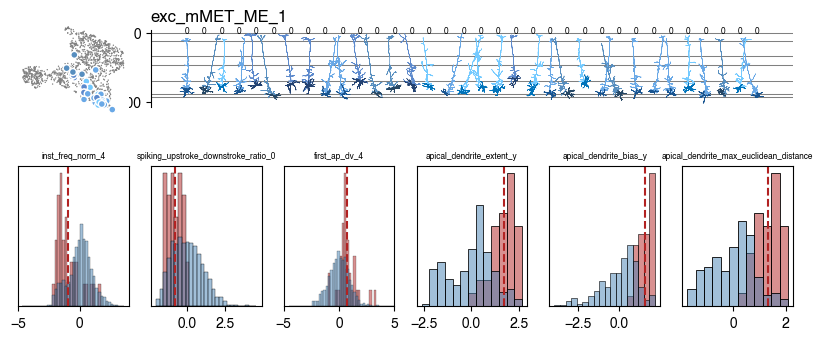

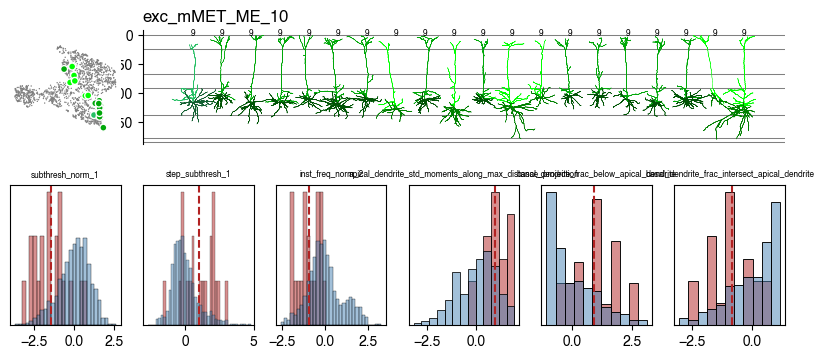

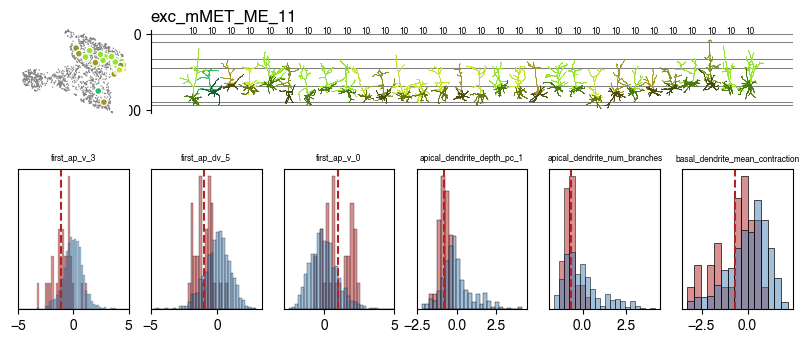

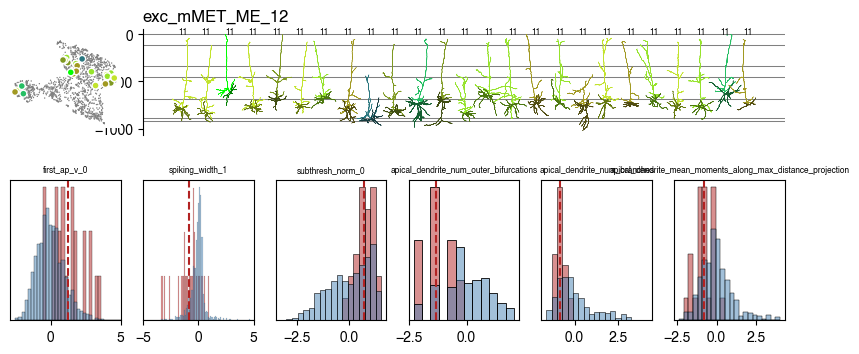

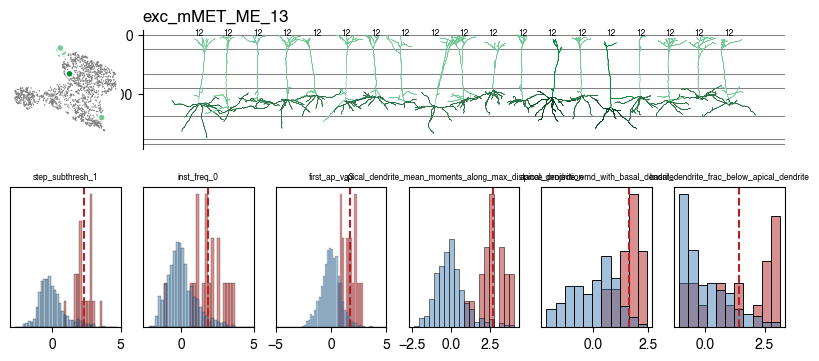

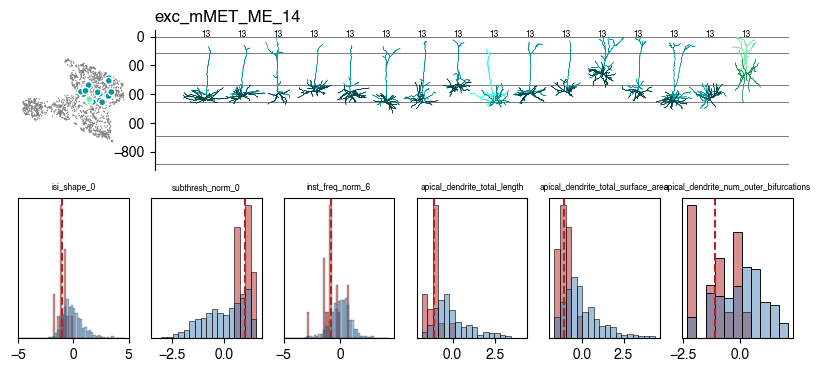

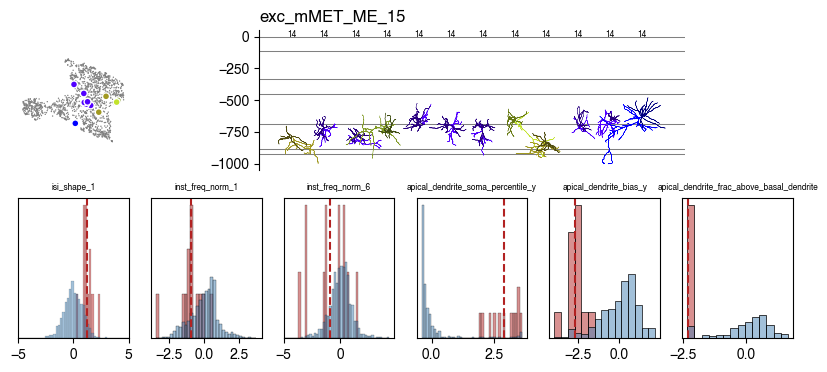

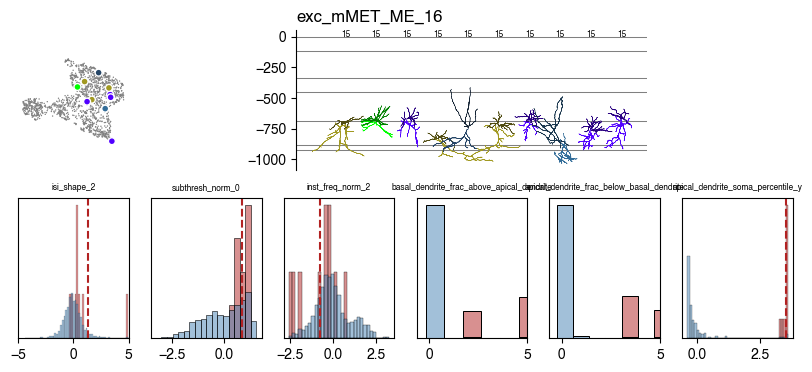

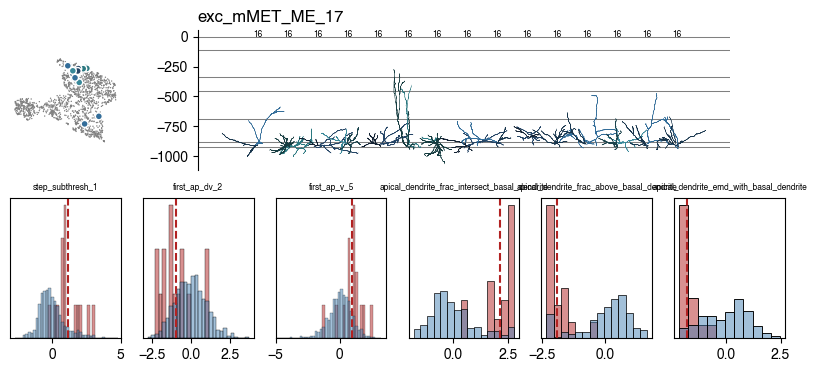

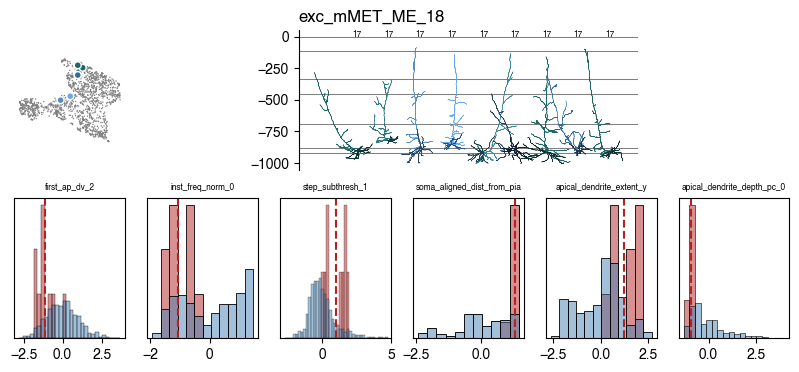

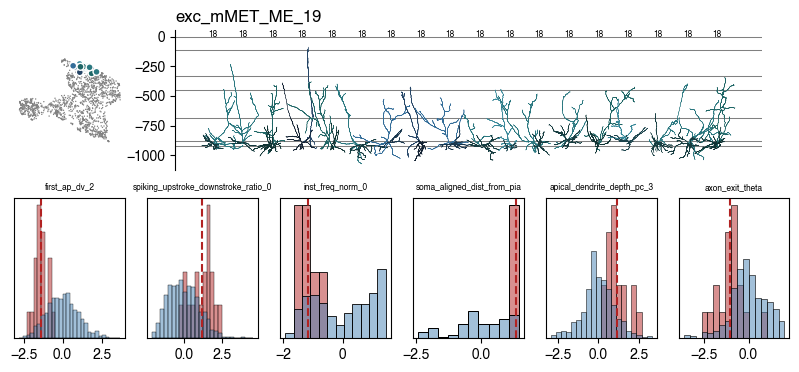

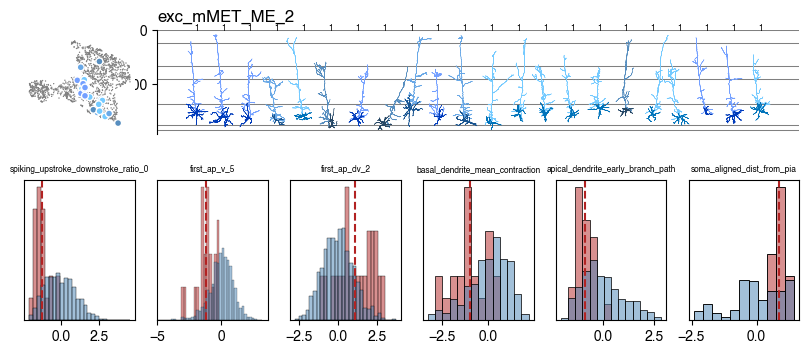

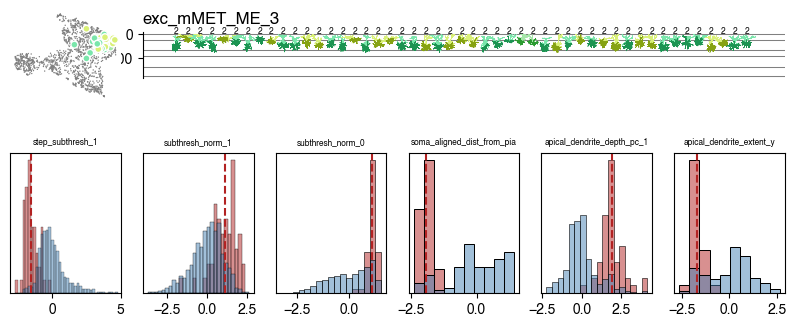

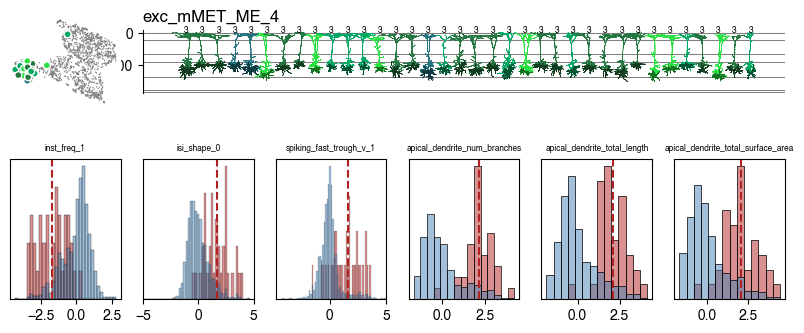

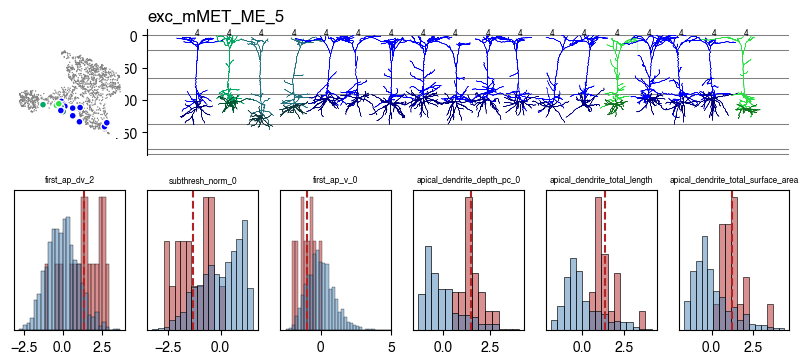

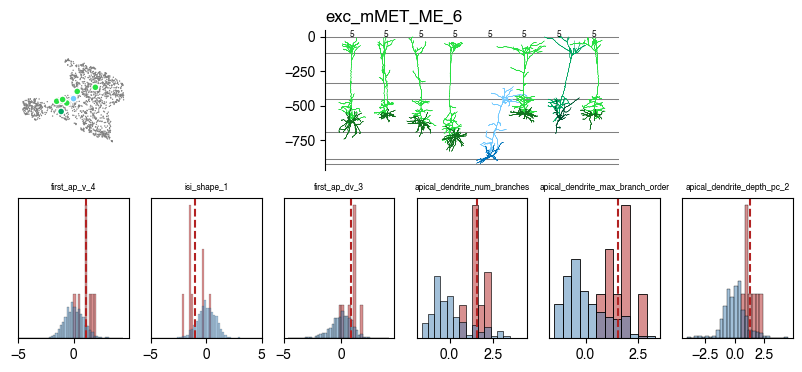

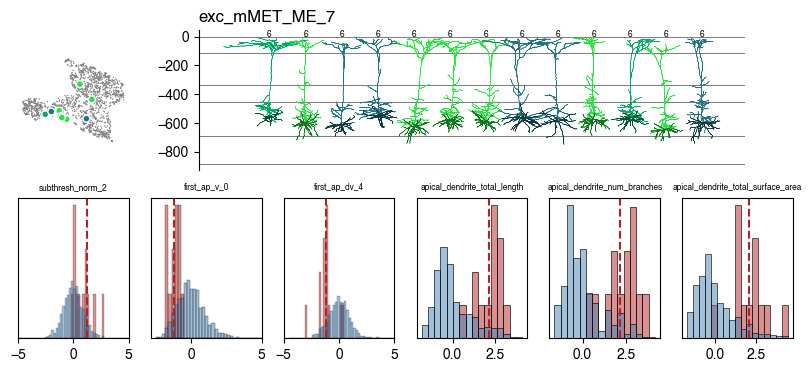

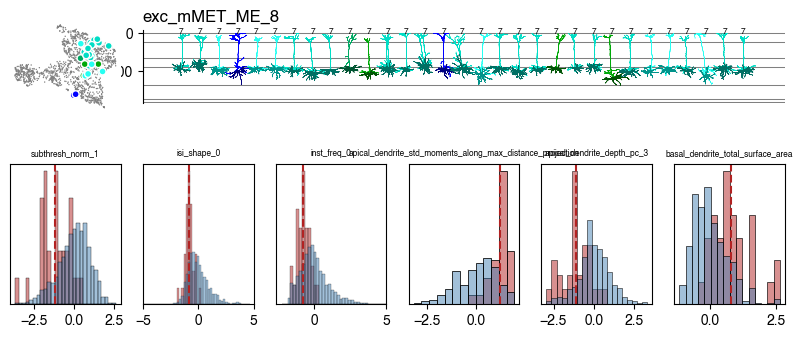

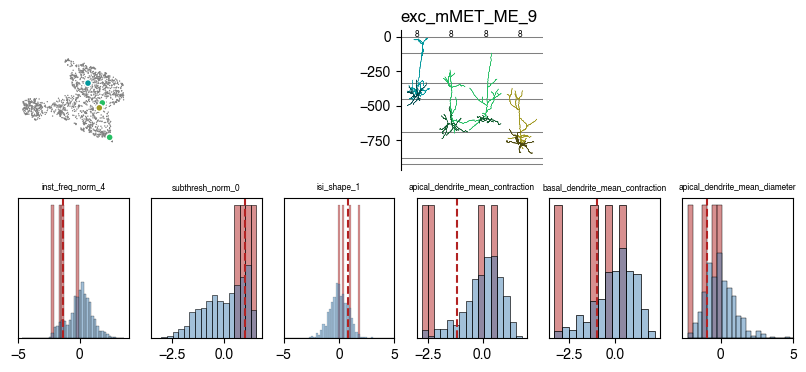

In [164]:
for me in sorted(me_types["0"].unique()):
    plt.figure(figsize=(10, 4))
    gs = gridspec.GridSpec(2, 6)

    ax = plt.subplot(gs[0, 1:])
    sub_df = me_types.loc[me_types["0"] == me, :]
    x_offset = 0
    sorter = np.argsort(unrefined_me_types.loc[sub_df.index, "0"].values)
    for spec_id in sub_df.index.values[sorter]:
        filename = f"../../morph_features/exc_mMET_swcs_Jan2025/layer_aligned_swcs/{spec_id}.swc"
        morph = ccfmorph.load_swc_as_dataframe(filename)
        x_offset += 250
        ttype = anno_df.set_index("spec_id_label").at[spec_id, "Tree_first_cl_label"]
        ttype_color = color_dict[ttype]
        unref_me = unrefined_me_types.at[spec_id, "0"]
        compartment_morph_df_plot(morph, ax, scale_factor=1, x_offset=x_offset, 
                                  compartment_colors={4: ttype_color, 3: adjust_lightness(ttype_color, 0.5)})
        ax.text(x_offset, 0, str(unref_me), fontsize=6, ha="center")
    ax.set_aspect("equal")
    for e in layer_edges:
        ax.axhline(-e, zorder=-5, color="gray", linewidth=0.75)

    sns.despine(ax=ax, bottom=True)
    ax.set_title(me, loc="left")
    ax.set_xticks([])

    ax = plt.subplot(gs[0, 0])
    ax.scatter(*umap_coords.T, color="gray", s=1, edgecolors='none')
    mask = ephys_df.index.isin(sub_df.index.values)
    inds = ephys_df.index.values[mask]
    colors = [color_dict[t] for t in anno_df.set_index("spec_id_label").loc[inds, "Tree_first_cl_label"]]
    ax.scatter(*umap_coords[mask, :].T, c=colors, s=25, edgecolors='white')
    ax.set_aspect("equal")
    sns.despine(ax=ax, left=True, bottom=True)
    ax.set(xticks=[], yticks=[])

    # ID distinguishing features
    # top 3 for ephys, morph

    inds = sub_df.index.values
    # ephys
    abs_avg_for_me =  ephys_df.loc[inds, :].mean(axis=0).apply(np.abs).sort_values()
    avg_for_me = ephys_df.loc[inds, :].mean(axis=0)
    
    for i in range(3):
        ax = plt.subplot(gs[1, i])
        feature = abs_avg_for_me.index[-(i + 1)]
        sns.histplot(
            {
                "all": ephys_df[feature].values,
                "me_type": ephys_df.loc[inds, feature],
            },
            stat="proportion",       
            common_norm=False,
            palette={"all": "steelblue", "me_type": "firebrick"},
            legend=False,
            ax=ax
        )
        ax.set_title(spca_lookup[int(feature)], fontsize=6)
        ax.set_yticks([])
        ax.set_ylabel("")
        ax.axvline(avg_for_me[feature], linestyle="dashed", color="firebrick")
        (x_left, x_right) = ax.get_xlim()
        new_left = max(-5, x_left)
        new_right = min(5, x_right)
        ax.set_xlim(left=new_left, right=new_right)

    # morph
    abs_avg_for_me =  morph_df.loc[inds, :].mean(axis=0).apply(np.abs).sort_values()
    avg_for_me = morph_df.loc[inds, :].mean(axis=0)
    
    for i in range(3):
        ax = plt.subplot(gs[1, i + 3])
        feature = abs_avg_for_me.index[-(i + 1)]
        sns.histplot(
            {
                "all": morph_df[feature].values,
                "me_type": morph_df.loc[inds, feature],
            },
            stat="proportion",       
            common_norm=False,
            palette={"all": "steelblue", "me_type": "firebrick"},
            legend=False,
            ax=ax
        )
        ax.set_title(feature, fontsize=6)
        ax.set_yticks([])
        ax.set_ylabel("")
        ax.axvline(avg_for_me[feature], linestyle="dashed", color="firebrick")
        (x_left, x_right) = ax.get_xlim()
        new_left = max(-5, x_left)
        new_right = min(5, x_right)
        ax.set_xlim(left=new_left, right=new_right)
    plt.savefig(f"me_type_review/{me}.png", dpi=300, bbox_inches="tight")

In [30]:
variants_df = pd.read_csv("../../me_clust_output/exc_met_mouse_me_clustering_Jan2025/elmo_cluster_variants.csv", index_col=0)

In [33]:
refined_met_type = 9

inds = me_types.index[me_types["0"] == refined_met_type]
inds

Index([642777215, 640106757, 645530172, 639910703, 792687812, 680973517,
       643798256, 603337985, 717313398, 825002523, 867650384, 680954928,
       899583778],
      dtype='int64')

In [35]:
variants_t_df = pd.merge(variants_df, anno_df.set_index("spec_id_label").loc[:, ["Tree_first_cl_label"]],
                         left_index=True, right_index=True)

In [37]:
variants_t_df.loc[inds, :].sort_values("Tree_first_cl_label")

,hc_conn_4_10,hc_conn_4_15,hc_conn_4_20,hc_conn_4_25,hc_conn_7_10,hc_conn_7_15,hc_conn_7_20,hc_conn_7_25,hc_conn_10_10,hc_conn_10_15,...,kmeans_combo_0.667_25,kmeans_combo_1_10,kmeans_combo_1_15,kmeans_combo_1_20,kmeans_combo_1_25,kmeans_combo_1.5_10,kmeans_combo_1.5_15,kmeans_combo_1.5_20,kmeans_combo_1.5_25,Tree_first_cl_label
867650384,2,0,7,7,0,4,9,9,1,4,...,14,8,12,1,14,8,1,1,23,L2/3 IT VISp Agmat
899583778,3,1,5,10,2,2,2,2,0,7,...,1,8,1,1,1,1,1,1,23,L2/3 IT VISp Agmat
642777215,2,0,17,3,2,2,2,4,7,3,...,5,1,1,1,1,1,1,1,1,L4 IT VISp Rspo1
640106757,0,2,3,0,2,2,2,2,0,7,...,5,1,1,1,1,8,1,1,23,L4 IT VISp Rspo1
645530172,3,1,5,10,3,3,4,10,4,1,...,20,1,6,6,8,8,10,10,23,L4 IT VISp Rspo1
639910703,0,2,3,11,2,2,2,2,0,7,...,5,4,12,12,1,8,1,1,23,L4 IT VISp Rspo1
792687812,3,1,5,8,3,3,4,10,0,7,...,20,1,1,1,1,1,1,1,1,L4 IT VISp Rspo1
680973517,0,2,3,0,2,2,2,2,3,14,...,20,4,4,15,11,6,8,1,23,L4 IT VISp Rspo1
643798256,3,1,5,8,2,2,2,2,0,7,...,1,1,1,1,1,1,1,1,23,L4 IT VISp Rspo1
717313398,7,7,15,15,2,2,2,4,1,4,...,5,1,1,1,1,8,1,1,23,L4 IT VISp Rspo1


In [174]:
morph_df.loc[inds, :].mean(axis=0).sort_values()

apical_dendrite_emd_with_basal_dendrite                      -1.640165
apical_dendrite_frac_above_basal_dendrite                    -1.633466
basal_dendrite_soma_percentile_y                             -1.412744
apical_dendrite_num_outer_bifurcations                       -1.241324
apical_dendrite_num_branches                                 -1.211982
axon_exit_theta                                              -1.194822
apical_dendrite_total_length                                 -1.150079
apical_dendrite_extent_y                                     -1.128853
apical_dendrite_max_branch_order                             -1.089028
apical_dendrite_total_surface_area                           -1.026605
apical_dendrite_bias_y                                       -1.013522
apical_dendrite_depth_pc_0                                   -0.960685
basal_dendrite_frac_below_apical_dendrite                    -0.877098
apical_dendrite_std_moments_along_max_distance_projection    -0.853493
basal_

In [175]:
ephys_df.loc[inds, :].mean(axis=0).sort_values()

9    -1.154541
40   -0.973229
6    -0.934274
48   -0.816208
34   -0.741502
        ...   
19    0.818064
33    0.949350
44    0.980600
18    1.100661
5     1.153828
Length: 62, dtype: float64

In [86]:
combo_morph_df = pd.merge(morph_df, me_types, left_index=True, right_index=True)

In [87]:
combo_morph_df = pd.merge(combo_morph_df, anno_df.set_index("spec_id_label").loc[:, ["Tree_first_cl_label"]],
                          left_index=True, right_index=True)

(0.0, 1.0)

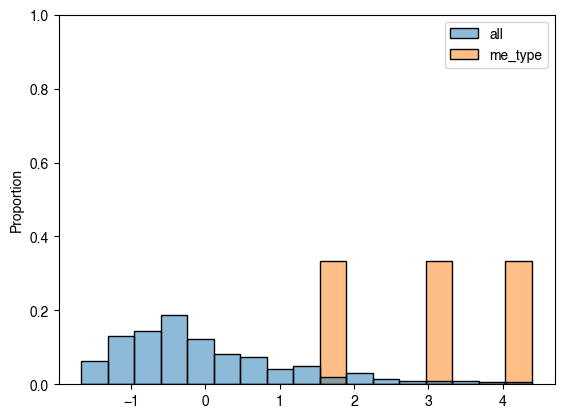

In [118]:
feature = "basal_dendrite_pct_above_apical_dendrite"
feature = "apical_dendrite_total_surface_area"

sns.histplot(
    {
        "all": morph_df[feature].values,
        "me_type": combo_morph_df.groupby("0").get_group(refined_met_type)[feature].values
    },
    stat="proportion",       
    common_norm=False,
    )

plt.ylim(0, 1)

In [119]:
combo_morph_df.groupby("0").get_group(refined_met_type).loc[:, [feature, "0", "Tree_first_cl_label"]]

,apical_dendrite_total_surface_area,0,Tree_first_cl_label
603481505,3.082096,exc_mMET_ME_5,L5 PT VISp C1ql2 Cdh13
823218199,4.392973,exc_mMET_ME_5,L5 PT VISp C1ql2 Ptgfr
895580896,1.676274,exc_mMET_ME_5,L5 PT VISp Lgr5


In [106]:
morph_raw_df = pd.read_csv("/allen/programs/celltypes/workgroups/ivscc/nathang/exc_mouse_met/derived_data/morph_features_mMET_exc_wide_raw.csv", index_col=0)

In [107]:
spec_id = 961238285

filename = f"../../morph_features/exc_mMET_swcs/upright_corrected_swcs/{spec_id}.swc"
morph = ccfmorph.load_swc_as_dataframe(filename)


In [108]:
morph_raw_df.at[spec_id, feature]

323.9936745075688

In [109]:
morph_raw_df.at[spec_id, "basal_dendrite_extent_y"]

188.5369076185218

In [99]:
morph_raw_df.at[spec_id, "basal_dendrite_intersect_below_apical_dendrite"]

KeyError: 'basal_dendrite_intersect_below_apical_dendrite'

3 green
4 firebrick


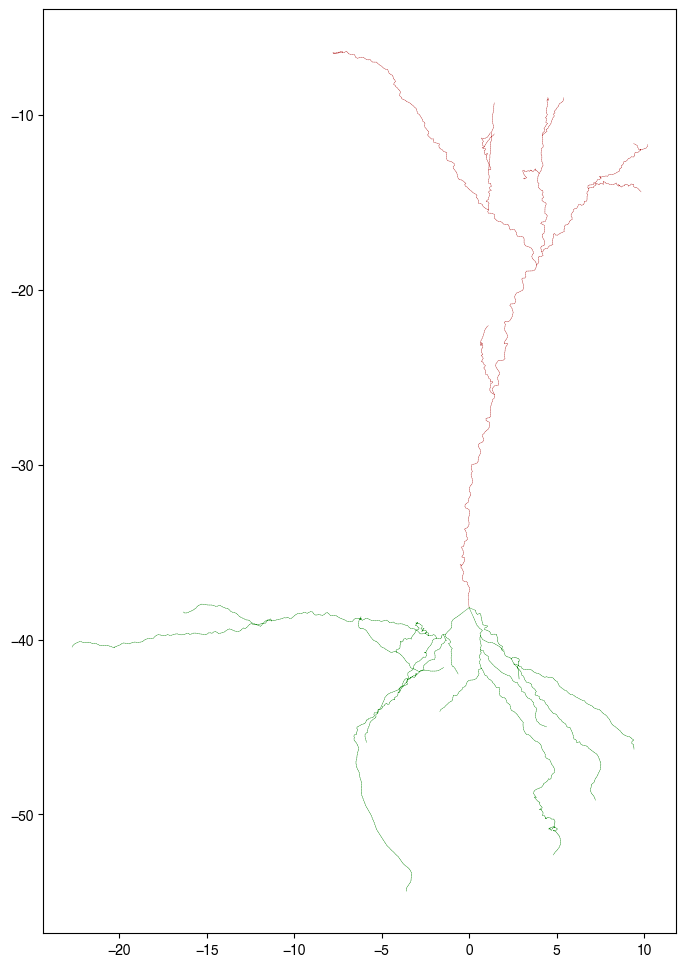

In [91]:
plt.figure(figsize=(12, 12))
compartment_morph_df_plot(morph, plt.gca(), compartment_colors={3: "green", 4: "firebrick"})
plt.gca().set_aspect("equal")

In [81]:
morph["type"].value_counts()

type
2    4976
3    1306
4     887
1       1
Name: count, dtype: int64

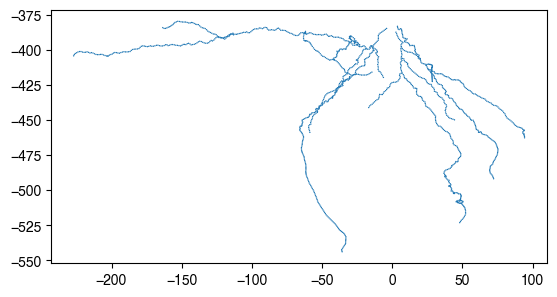

In [84]:
plt.scatter(morph.loc[morph.type == 3, "x"].values, 
            morph.loc[morph.type == 3, "y"].values,
            s=1, edgecolors='none')
plt.gca().set_aspect("equal")

In [100]:
sk_morph_df = pd.read_csv("../../ivscc_morph_reference/exc_ivscc_features_wide_unnormalized.csv", index_col=0)

In [ ]:
sk_morph_df.basal_dendrite_frac_above_apical_dendrite

In [103]:
sk_morph_df.loc[spec_id, "basal_dendrite_frac_above_apical_dendrite"]

0.0

In [110]:
anno_df.set_index('spec_id_label').loc[711573106, ["Tree_first_cl_label", "Tree_call_label"]]

Tree_first_cl_label    L5 IT VISp Batf3
Tree_call_label                    Core
Name: 711573106, dtype: object

In [112]:
ephys_df.loc[711573106, :]

0    -0.440934
1    -0.068119
2    -0.026133
3    -1.427583
4     0.019371
        ...   
57   -1.761154
58    0.530919
59   -0.437413
60   -1.870574
61    1.387436
Name: 711573106, Length: 62, dtype: float64

In [82]:
ephys_df.values.shape

(1528, 62)

In [85]:
np.corrcoef(ephys_df.values, rowvar=True).shape

(1528, 1528)

In [89]:
np.corrcoef(ephys_df.iloc[0, :].values, ephys_df.iloc[1, :].values)

array([[1.        , 0.48656349],
       [0.48656349, 1.        ]])

In [91]:
np.corrcoef(ephys_df.iloc[:2, :], rowvar=False)

array([[ 1.,  1., -1., ..., -1., -1.,  1.],
       [ 1.,  1., -1., ..., -1., -1.,  1.],
       [-1., -1.,  1., ...,  1.,  1., -1.],
       ...,
       [-1., -1.,  1., ...,  1.,  1., -1.],
       [-1., -1.,  1., ...,  1.,  1., -1.],
       [ 1.,  1., -1., ..., -1., -1.,  1.]])

In [20]:
sorted_me_types = sorted(me_types["0"].unique())

In [16]:
ephys_corr_df = pd.DataFrame(np.corrcoef(ephys_df.values), index=ephys_df.index, columns=ephys_df.index)

In [17]:
morph_corr_df = pd.DataFrame(np.corrcoef(morph_df), index=morph_df.index, columns=morph_df.index)

In [18]:
me_types.sort_values("0")

,0
831254527,exc_mMET_ME_1
927797864,exc_mMET_ME_1
903864968,exc_mMET_ME_1
902000094,exc_mMET_ME_1
863515305,exc_mMET_ME_1
...,...
681937682,exc_mMET_ME_8
961238333,exc_mMET_ME_9
680973517,exc_mMET_ME_9
701075085,exc_mMET_ME_9


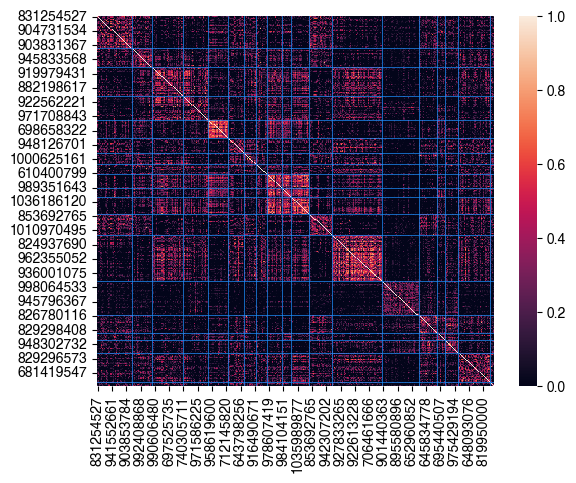

In [21]:
sns.heatmap(ephys_corr_df.loc[me_types.sort_values("0").index, me_types.sort_values("0").index], vmin=0)
line_position = 0
for v in me_types.value_counts()[sorted_me_types]:
    line_position += v
    plt.axvline(line_position, color="dodgerblue", lw=0.5)
    plt.axhline(line_position, color="dodgerblue", lw=0.5)


In [22]:
inds = np.tril_indices_from(ephys_corr_df.loc[me_types.index, me_types.index].values, -1)

In [30]:
ephys_corr_threshold = np.quantile(ephys_corr_df.loc[me_types.index, me_types.index].values[inds], 0.95)

In [31]:
 np.quantile(ephys_corr_df.loc[me_types.index, me_types.index].values[inds], 0.95)

0.4125361327392446

In [32]:
 np.quantile(ephys_corr_df.loc[me_types.index, me_types.index].values[inds], 0.98)

0.5289610595272144

In [33]:
ephys_corr_threshold

0.4125361327392446

In [34]:
(389 * 388) / 2

75466.0

In [35]:
np.quantile(ephys_corr_df.loc[me_types.index, me_types.index].values[inds], 0.95)

0.4125361327392446

In [39]:
(ephys_corr_df.loc[me_types.index, me_types.index].values[inds] > .4).mean()

0.05435560384809053

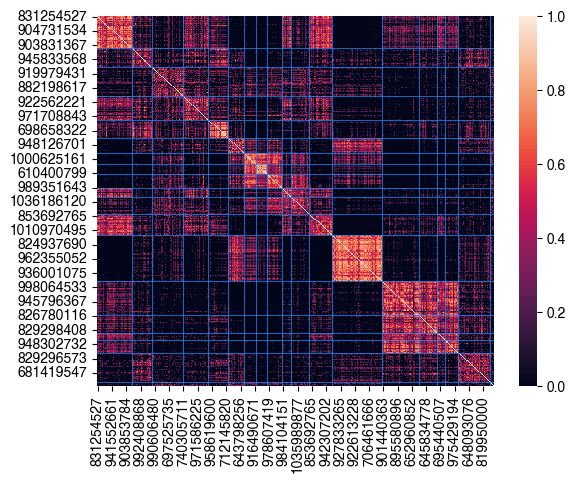

In [40]:
sns.heatmap(morph_corr_df.loc[me_types.sort_values("0").index, me_types.sort_values("0").index], vmin=0)
line_position = 0
for v in me_types.value_counts()[sorted_me_types]:
    line_position += v
    plt.axvline(line_position, color="dodgerblue", lw=0.5)
    plt.axhline(line_position, color="dodgerblue", lw=0.5)


In [41]:
(morph_corr_df.loc[me_types.index, me_types.index].values[inds] > .5).mean()

0.07359605650226592

In [42]:
(morph_corr_df.loc[me_types.index, me_types.index].values[inds] > .55).mean()

0.05663477592558238

In [43]:
select_marker_genes = pd.read_csv("../data/ref_tasic_select_genes.csv", index_col=0)

In [44]:
exc_select_marker_genes = np.genfromtxt("../data/exc_type_markers_tasic_2018_supp_table_9.txt", dtype=str)
exc_select_marker_genes

array(['2310002F09Rik', '3632454L22Rik', '4930555B11Rik', '8030453O22Rik',
       '9330158H04Rik', 'A730090H04Rik', 'A830009L08Rik', 'Abracl',
       'Adamts2', 'Adora2a', 'Adra1b', 'Adssl1', 'Agmat', 'Aldh1l1',
       'Arhgap25', 'Asb2', 'Batf3', 'Bcan', 'Bglap3', 'Bhlhe22', 'Blnk',
       'Bmp3', 'Brinp3', 'C030013G03Rik', 'C1ql2', 'Car1', 'Car2', 'Car3',
       'Ccdc80', 'Ccnd1', 'Cd24a', 'Cd52', 'Cdh10', 'Cdh13', 'Cdh9',
       'Cdhr1', 'Cenpa', 'Chn2', 'Chrm2', 'Chrna5', 'Chrna6', 'Chrnb3',
       'Clic5', 'Cntnap3', 'Col18a1', 'Col23a1', 'Col24a1', 'Col8a1',
       'Coro6', 'Cplx3', 'Cpne2', 'Cpne7', 'Ctsz', 'Ctxn3', 'Cux2',
       'Defb1', 'Depdc7', 'Diap3', 'E330017L17Rik', 'Endou', 'Ephb1',
       'Erg', 'Etv4', 'Fam101b', 'Fam19a1', 'Fam20a', 'Fbxl7', 'Fn1',
       'Fndc5', 'Foxp2', 'Frzb', 'Gal', 'Galr1', 'Glra3', 'Gpr139',
       'Gpr39', 'Gpr88', 'Grik1', 'Hgf', 'Htr1d', 'Igfbp7', 'Igsf3',
       'Itga7', 'Klk9', 'Krt80', 'Lce3c', 'Lefty2', 'Lgr5', 'Lhfpl2',
       'Lhx2',

In [45]:
exc_de_genes = pd.read_csv("../derived_data/ref_all_exc_de_genes.csv", index_col=0)
exc_de_genes

,x
1,Synpr
2,Cplx3
3,Ctgf
4,Tnmd
5,Npy
...,...
777,Il13ra1
778,Kcnv1
779,LOC105243988
780,Bpifa1


In [46]:
exc_select_marker_genes = exc_de_genes["x"].values

In [47]:
gene_data_file = "/allen/programs/celltypes/workgroups/rnaseqanalysis/shiny/patch_seq/star/archived/mouse_patchseq_VISp_20210818_collapsed40_cpm/data.feather"

In [48]:
genes_df = pd.read_feather(gene_data_file, columns=["sample_id"] + exc_select_marker_genes.tolist())

In [49]:
genes_df.set_index("sample_id", inplace=True)

In [50]:
genes_df

,Synpr,Cplx3,Ctgf,Tnmd,Npy,Tnfaip6,Serpinb2,Atf3,Tac1,Trh,...,C730002L08Rik,Olfr78,Aplnr,Rab26,Igfbp2,Il13ra1,Kcnv1,LOC105243988,Bpifa1,Itm2c
sample_id,,,,,,,,,,,,,,,,,,,,,
P1S4_170807_003_A01,0.000000,0.0,0.000000,0.982061,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,0.000000,0.0,0.0,0.000000,0.000000,0.0,156.147651,0.0,0.0,477.281499
P1S4_190214_003_A01,61.562941,0.0,0.000000,0.000000,0.000000,19.889566,0.0,0.000000,0.0,0.0,...,149.645303,0.0,0.0,47.356108,109.866172,0.0,110.813294,0.0,0.0,472.613962
P1S4_190624_004_A01,0.000000,0.0,0.000000,0.000000,0.000000,1.992443,0.0,719.271802,0.0,0.0,...,62.761944,0.0,0.0,0.000000,0.000000,0.0,81.690149,0.0,0.0,434.352501
P1S4_190628_007_A01,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,719.946386,0.0,0.0,...,54.189513,0.0,0.0,0.000000,76.307681,0.0,0.000000,0.0,0.0,446.787004
P1S4_190725_002_A01,74.921333,0.0,0.000000,0.000000,0.000000,74.921333,0.0,0.000000,0.0,0.0,...,44.397827,0.0,0.0,0.000000,0.000000,0.0,110.069612,0.0,0.0,308.934878
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SM-GE8ZO_S093_E1-50,442.095914,0.0,0.000000,0.000000,0.000000,49.897959,0.0,0.000000,0.0,0.0,...,241.506120,0.0,0.0,88.818366,24.948979,0.0,120.753060,0.0,0.0,1210.524477
SM-GE91H_S317_E1-50,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.0,0.0,...,20.795468,0.0,0.0,307.772930,0.000000,0.0,74.863686,0.0,0.0,447.102567
SQ-80004_S28_E1-50,2198.418621,0.0,0.000000,0.000000,438.134763,0.000000,0.0,0.000000,0.0,0.0,...,0.000000,0.0,0.0,68.043656,0.000000,0.0,0.000000,0.0,0.0,201.918167


In [51]:
met_sample_ids = anno_df.set_index("spec_id_label").loc[me_types.index, "sample_id"].values
genes_met_df = genes_df.loc[met_sample_ids, :].copy()


In [52]:
genes_corr_df = pd.DataFrame(np.corrcoef(genes_met_df.apply(np.log1p)), index=me_types.index, columns=me_types.index)

In [53]:
me_types.value_counts()[sorted_me_types]

0             
exc_mMET_ME_1     34
exc_mMET_ME_10    20
exc_mMET_ME_11    30
exc_mMET_ME_12    25
exc_mMET_ME_13    19
exc_mMET_ME_14    16
exc_mMET_ME_15    12
exc_mMET_ME_16    10
exc_mMET_ME_17    15
exc_mMET_ME_18     9
exc_mMET_ME_19    18
exc_mMET_ME_2     22
exc_mMET_ME_3     49
exc_mMET_ME_4     36
exc_mMET_ME_5     18
exc_mMET_ME_6      8
exc_mMET_ME_7     13
exc_mMET_ME_8     31
exc_mMET_ME_9      4
Name: count, dtype: int64

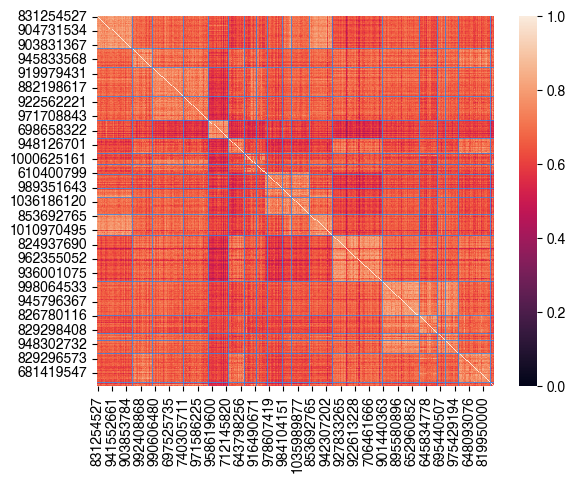

In [55]:
sns.heatmap(genes_corr_df.loc[me_types.sort_values("0").index, me_types.sort_values("0").index], vmin=0)

line_position = 0
for v in me_types.value_counts()[sorted_me_types]:
    line_position += v
    plt.axvline(line_position, color="dodgerblue", lw=0.5)
    plt.axhline(line_position, color="dodgerblue", lw=0.5)


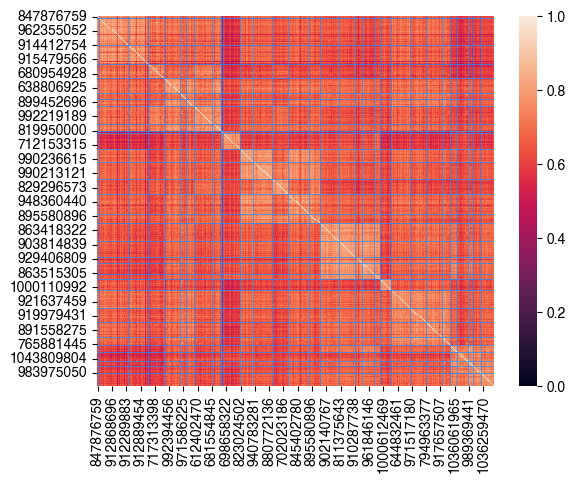

In [56]:
ttype_ind_order = ttypes_df.loc[me_types.index, :].sort_values(0).index
sorted_t_types = sorted(ttypes_df.loc[me_types.index, 0].unique())

sns.heatmap(genes_corr_df.loc[ttype_ind_order, ttype_ind_order], vmin=0)

line_position = 0
for v in ttypes_df.loc[me_types.index, 0].value_counts()[sorted_t_types]:
    line_position += v
    plt.axvline(line_position, color="dodgerblue", lw=0.5)
    plt.axhline(line_position, color="dodgerblue", lw=0.5)


In [57]:
sorted_t_types

['L2/3 IT VISp Adamts2',
 'L2/3 IT VISp Agmat',
 'L2/3 IT VISp Rrad',
 'L4 IT VISp Rspo1',
 'L5 IT VISp Batf3',
 'L5 IT VISp Col27a1',
 'L5 IT VISp Col6a1 Fezf2',
 'L5 IT VISp Hsd11b1 Endou',
 'L5 IT VISp Whrn Tox2',
 'L5 NP VISp Trhr Cpne7',
 'L5 NP VISp Trhr Met',
 'L5 PT VISp C1ql2 Cdh13',
 'L5 PT VISp C1ql2 Ptgfr',
 'L5 PT VISp Chrna6',
 'L5 PT VISp Krt80',
 'L5 PT VISp Lgr5',
 'L6 CT VISp Ctxn3 Brinp3',
 'L6 CT VISp Ctxn3 Sla',
 'L6 CT VISp Gpr139',
 'L6 CT VISp Krt80 Sla',
 'L6 CT VISp Nxph2 Wls',
 'L6 IT VISp Car3',
 'L6 IT VISp Col18a1',
 'L6 IT VISp Col23a1 Adamts2',
 'L6 IT VISp Penk Col27a1',
 'L6 IT VISp Penk Fst',
 'L6b Col8a1 Rprm',
 'L6b P2ry12',
 'L6b VISp Col8a1 Rxfp1',
 'L6b VISp Crh',
 'L6b VISp Mup5']

In [58]:
(genes_corr_df.loc[me_types.index, me_types.index].values[inds] > .85).mean()

0.00047703601621922455

<Axes: ylabel='Count'>

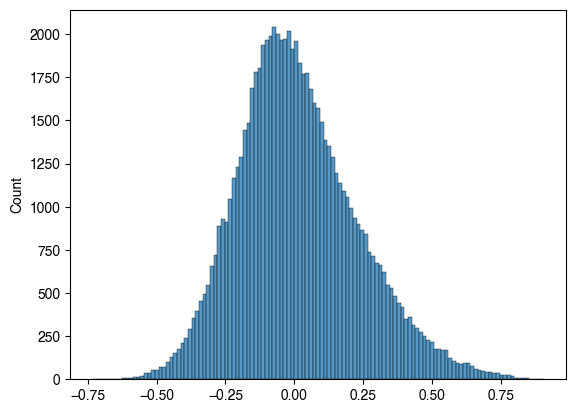

In [62]:
sns.histplot((ephys_corr_df.loc[me_types.index, me_types.index].values[inds]))

<Axes: ylabel='Count'>

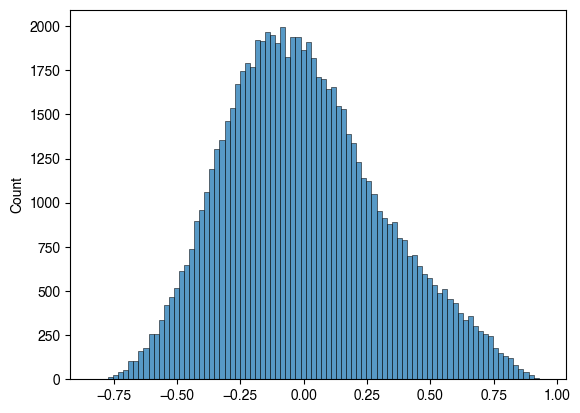

In [63]:
sns.histplot((morph_corr_df.loc[me_types.index, me_types.index].values[inds]))

<Axes: ylabel='Count'>

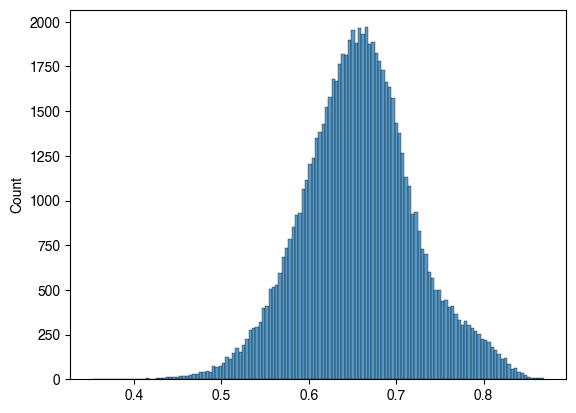

In [60]:
sns.histplot((genes_corr_df.loc[me_types.index, me_types.index].values[inds]))

In [61]:
(genes_corr_df.loc[me_types.index, me_types.index].values[inds] > .85).mean()

0.00047703601621922455

In [64]:
ephys_corr_df.to_csv("../derived_data/met_corr_ephys_Jan2025.csv")

In [65]:
morph_corr_df.to_csv("../derived_data/met_corr_morph_Jan2025.csv")

In [66]:
genes_corr_df.to_csv("../derived_data/met_corr_genes_Jan2025.csv")

In [68]:
avg_corr_df = (ephys_corr_df.loc[me_types.index, me_types.index] + 
               morph_corr_df.loc[me_types.index, me_types.index] + 
               genes_corr_df.loc[me_types.index, me_types.index]) / 3

In [69]:
avg_corr_df.values[:5, :5]

array([[1.        , 0.13599795, 0.37135909, 0.25593667, 0.11453534],
       [0.13599795, 1.        , 0.12811143, 0.26961562, 0.22650369],
       [0.37135909, 0.12811143, 1.        , 0.4212264 , 0.22771779],
       [0.25593667, 0.26961562, 0.4212264 , 1.        , 0.10192827],
       [0.11453534, 0.22650369, 0.22771779, 0.10192827, 1.        ]])

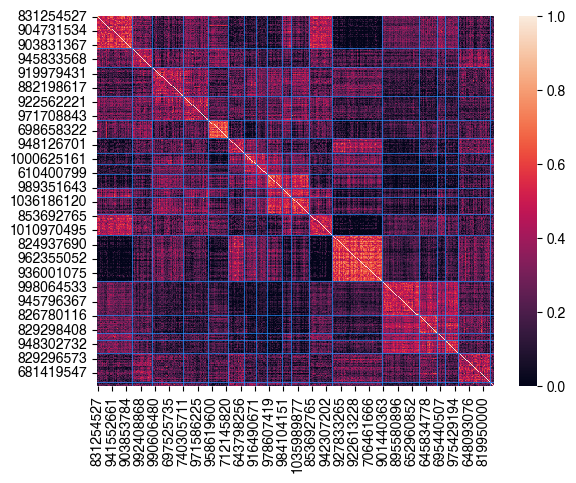

In [70]:
sns.heatmap(avg_corr_df.loc[me_types.sort_values("0").index, me_types.sort_values("0").index], vmin=0 , vmax=1)
line_position = 0
for v in me_types.value_counts()[sorted_me_types]:
    line_position += v
    plt.axvline(line_position, color="dodgerblue", lw=0.5)
    plt.axhline(line_position, color="dodgerblue", lw=0.5)


In [71]:
avg_corr_df.values

array([[1.        , 0.13599795, 0.37135909, ..., 0.30659842, 0.21277782,
        0.41037386],
       [0.13599795, 1.        , 0.12811143, ..., 0.40251913, 0.20446704,
        0.27436075],
       [0.37135909, 0.12811143, 1.        , ..., 0.21807771, 0.28595657,
        0.3686742 ],
       ...,
       [0.30659842, 0.40251913, 0.21807771, ..., 1.        , 0.23832978,
        0.17020602],
       [0.21277782, 0.20446704, 0.28595657, ..., 0.23832978, 1.        ,
        0.47958652],
       [0.41037386, 0.27436075, 0.3686742 , ..., 0.17020602, 0.47958652,
        1.        ]])

In [72]:
np.quantile(avg_corr_df.values[inds], 0.99)

0.6377486018662736

In [73]:
np.quantile(avg_corr_df.values[inds], 0.985)

0.6100184566794066

In [74]:
np.quantile(avg_corr_df.values[inds], 0.98)

0.5880822062714984

In [144]:
inds[0]

array([  1,   2,   2, ..., 388, 388, 388])

In [148]:
from sklearn.decomposition import PCA

In [152]:
ephys_df.shape

(1528, 62)

In [180]:
morph_df.shape

(389, 50)

In [153]:
genes_df.shape

(14479, 4020)

In [184]:
all_et_sample_ids = anno_df.set_index("spec_id_label").loc[ephys_df.index, "sample_id"].values

In [183]:
n_genes_detected = anno_df.set_index("spec_id_label").loc[ephys_df.index, "genes_label"].values

In [185]:
et_genes_df = genes_df.loc[all_et_sample_ids, :].copy()

In [186]:
et_genes_df.shape

(1528, 4020)

In [190]:
et_genes_pcs = PCA(n_components=50).fit_transform((et_genes_df - et_genes_df.mean(axis=0)).values)

In [209]:
et_genes_pc_df = pd.DataFrame(et_genes_pcs, index=ephys_df.index)

In [195]:
qc_corr = np.corrcoef(n_genes_detected, et_genes_pcs, rowvar=False)

In [198]:
qc_corr[0, :]

array([ 1.        ,  0.18258397,  0.31478695,  0.05819563, -0.05883165,
        0.10201224,  0.03488393, -0.11055804, -0.0298705 ,  0.05731607,
        0.18580264, -0.18135075,  0.00305691,  0.05651933,  0.08450365,
       -0.03183649,  0.04879644,  0.02744505, -0.02005217, -0.03090199,
        0.01392816, -0.09364607, -0.04841492,  0.02558759,  0.0016493 ,
       -0.04031336, -0.02821308,  0.06013036, -0.04113967, -0.08685749,
       -0.01791741, -0.10137938,  0.05272705,  0.02209363,  0.01958821,
       -0.09604996,  0.07343939, -0.02553464,  0.00217513,  0.05367668,
        0.01159341,  0.0575698 , -0.0282409 ,  0.09686788,  0.11775517,
        0.03835697,  0.03063605,  0.0549939 ,  0.08405734, -0.00747666,
        0.01771123])

In [201]:
# check if any are strongly correlated with number of genes detected
qc_corr[0, 1:].max()

0.314786954088471

In [272]:
from scipy.spatial.distance import cdist, pdist, squareform, euclidean

In [318]:
e_dist_df = pd.DataFrame(squareform(pdist(ephys_df.loc[me_types.index, '23':'24'])), index=me_types.index, columns=me_types.index)

<Axes: >

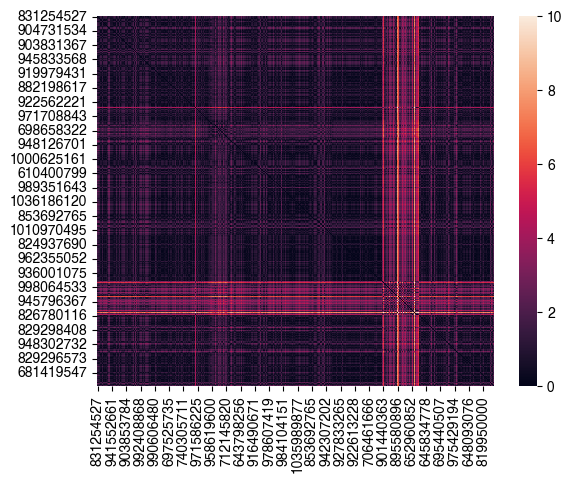

In [319]:
sns.heatmap(e_dist_df.loc[me_types.sort_values("0").index, me_types.sort_values("0").index], vmin=0, vmax=10)

In [320]:
ephys_w_me_df = pd.merge(ephys_df, me_types, left_index=True, right_index=True)

<Axes: xlabel='24', ylabel='0_y'>

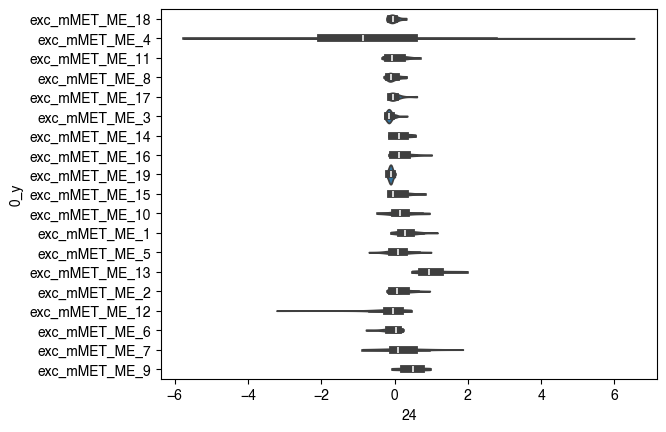

In [329]:
sns.violinplot(
    data=ephys_w_me_df,
    y="0_y",
    x="24",
    width=1,
    cut=0
)

In [326]:
ephys_df['20']

908902400    1.097049
965091329   -0.164776
978149378    0.051918
834891776    0.823044
897003522    1.072134
               ...   
972492789    1.064390
902029302    0.714344
826798072   -0.103627
645369849   -0.004122
831254527   -1.364318
Name: 20, Length: 1528, dtype: float64

In [274]:
me_5_ids = me_types.index[me_types["0"] == "exc_mMET_ME_3"]

In [275]:
len(me_5_ids)

49

In [276]:
e_simil_df = 1 / e_dist_df

<Axes: >

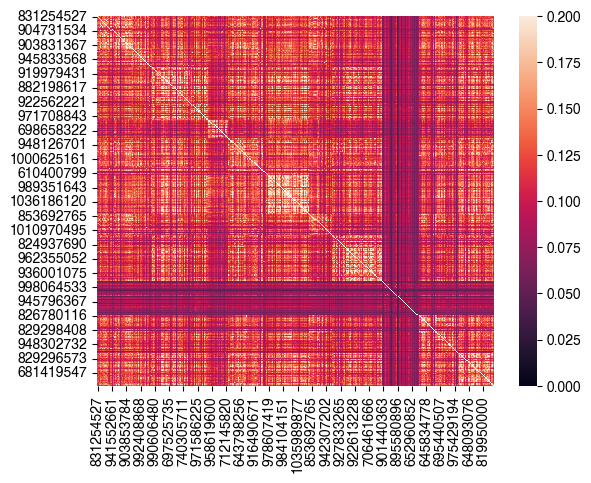

In [277]:
sns.heatmap(e_simil_df.loc[me_types.sort_values("0").index, me_types.sort_values("0").index], vmin=0, vmax=0.2)

In [278]:
ephys_df.loc[me_5_ids, :].mean().min()

-1.5177315948076398

In [279]:
euclidean(ephys_df.loc[me_5_ids[1], :].values, ephys_df.loc[me_5_ids[2], :].values)

6.873085263421702

In [280]:
euclidean(ephys_df.loc[me_5_ids[1], :].values, ephys_df.loc[me_5_ids[2], :].values)

6.873085263421702

<Axes: >

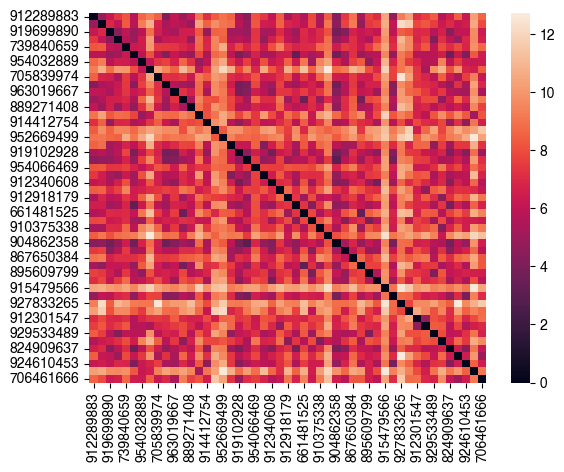

In [281]:
sns.heatmap(e_dist_df.loc[me_5_ids, me_5_ids], vmin=0)

In [229]:
m_dist_df = pd.DataFrame(squareform(pdist(morph_df.loc[me_types.index, :])), index=me_types.index, columns=me_types.index)

In [230]:
m_simil_df = 1 / m_dist_df

<Axes: >

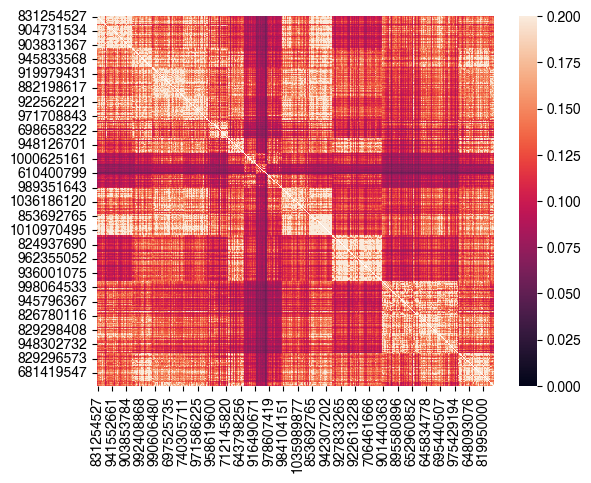

In [231]:
sns.heatmap(m_simil_df.loc[me_types.sort_values("0").index, me_types.sort_values("0").index], vmin=0, vmax=0.2)

In [241]:
1 / squareform(pdist(et_genes_pc_df.loc[me_types.index, :]))

/tmp/ipykernel_931212/2750062344.py:1: RuntimeWarning: divide by zero encountered in divide
  1 / squareform(pdist(et_genes_pc_df.loc[me_types.index, :]))


array([[           inf, 6.31235866e-05, 7.48401728e-05, ...,
        6.92646666e-05, 9.04404829e-05, 9.55265260e-05],
       [6.31235866e-05,            inf, 5.78693422e-05, ...,
        6.35814801e-05, 5.85611505e-05, 5.30442198e-05],
       [7.48401728e-05, 5.78693422e-05,            inf, ...,
        9.71083413e-05, 8.03479025e-05, 7.72349421e-05],
       ...,
       [6.92646666e-05, 6.35814801e-05, 9.71083413e-05, ...,
                   inf, 7.37999870e-05, 8.12362690e-05],
       [9.04404829e-05, 5.85611505e-05, 8.03479025e-05, ...,
        7.37999870e-05,            inf, 1.09423902e-04],
       [9.55265260e-05, 5.30442198e-05, 7.72349421e-05, ...,
        8.12362690e-05, 1.09423902e-04,            inf]])

In [254]:
t_dist_df = pd.DataFrame(squareform(pdist(et_genes_pc_df.loc[me_types.index, :])), index=me_types.index, columns=me_types.index)

In [255]:
t_simil_df = 1 / t_dist_df

<Axes: >

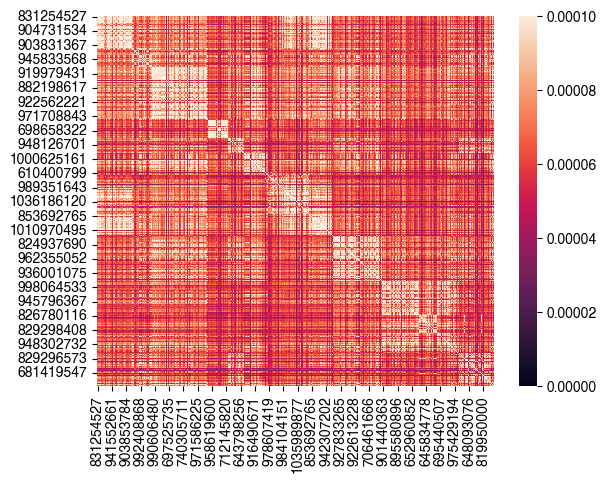

In [257]:
sns.heatmap(t_simil_df.loc[me_types.sort_values("0").index, me_types.sort_values("0").index], vmin=0, vmax=1e-4)

In [168]:
morph_corr_df.iloc[0, :]

specimen_id
601628311     1.000000
603229579     0.084581
603337985    -0.105976
603481505    -0.407298
603511210     0.164431
                ...   
1036259470   -0.302373
1039243792   -0.109373
1039273993    0.005310
1039503078    0.199119
1043809804   -0.039862
Name: 601628311, Length: 389, dtype: float64

In [169]:
sorter = np.argsort(morph_corr_df.iloc[0, :].values)

array([358, 277, 124, 284, 360, 268,   3, 123,  32, 249, 210,  30,  77,
        44,  57,  29, 381, 368, 363, 111,  66,  65,  25, 148, 247, 149,
       165, 359,  47, 221,  41, 333, 384, 273, 211, 242, 150, 382, 278,
        71,  73, 106, 160, 135, 186, 318, 303,  39,  70,   6, 208, 192,
       272, 222, 143, 167,  34, 259, 176, 218, 313,  78, 120, 195, 286,
        56,  69, 319, 154, 248, 137, 114, 252, 108, 153, 188,  26, 346,
       345, 372,  49, 171, 131, 276, 125, 289,  64,  36,  79, 226, 316,
       262, 327, 174, 270,  54, 128,  76, 104, 267, 355, 145, 263, 198,
       322, 115, 163, 347, 130, 349,  31, 379, 302, 344, 216, 332, 119,
        51, 305,  35, 227, 373, 357,  63, 274, 385,  88, 292, 173, 330,
         2, 144,  19, 312, 181, 132,  74, 193, 164, 205, 237,  18,  12,
       369, 142, 367, 308, 323, 212, 329,  59, 136, 264, 246, 113, 311,
       213, 275, 162, 236, 375,  84, 341, 374, 220, 383, 240, 209, 260,
        75, 285, 243, 271,  72, 199, 118,   9, 166, 388, 235, 20

In [178]:
morph_corr_df.iloc[0, :].values[sorter].shape

(389,)

In [179]:
sorter[-16:-1]

array([ 92, 296, 109,  17,  82, 298,  86,  93,  87,  83, 301, 342,  48,
        81, 320])

In [372]:
clusters

array(['L6 CT VISp Ctxn3 Sla', 'L6 CT VISp Ctxn3 Sla', 'L5 PT VISp Krt80',
       ..., 'L5 PT VISp Lgr5', 'L4 IT VISp Rspo1', 'L6 CT VISp Ctxn3 Sla'],
      dtype=object)

In [407]:
inds

array([680973517, 961238333, 971647853, 701075085])

# Viewing particular cells

[[], []]

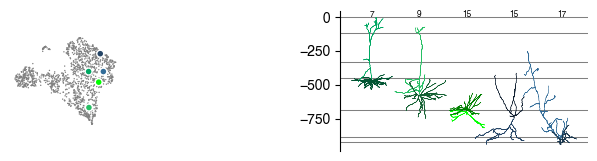

In [21]:
selected_cell_list = [603511210, 645529777, 694841940, 982558622, 984104151]

plt.figure(figsize=(10, 4))
gs = gridspec.GridSpec(2, 6)


ax = plt.subplot(gs[0, 1:])
x_offset = 0
for spec_id in selected_cell_list:
    filename = f"../../morph_features/exc_mMET_swcs_Jan2025/layer_aligned_swcs/{spec_id}.swc"
    morph = ccfmorph.load_swc_as_dataframe(filename)
    x_offset += 350
    ttype = anno_df.set_index("spec_id_label").at[spec_id, "Tree_first_cl_label"]
    ttype_color = color_dict[ttype]
    unref_me = unrefined_me_types.at[spec_id, "0"]
    compartment_morph_df_plot(morph, ax, scale_factor=1, x_offset=x_offset, 
                              compartment_colors={4: ttype_color, 3: adjust_lightness(ttype_color, 0.5)})
    ax.text(x_offset, 0, str(unref_me), fontsize=6, ha="center")
ax.set_aspect("equal")
for e in layer_edges:
    ax.axhline(-e, zorder=-5, color="gray", linewidth=0.75)

sns.despine(ax=ax, bottom=True)
ax.set_xticks([])

ax = plt.subplot(gs[0, 0])
ax.scatter(*umap_coords.T, color="gray", s=1, edgecolors='none')
mask = ephys_df.index.isin(selected_cell_list)
inds = ephys_df.index.values[mask]
colors = [color_dict[t] for t in anno_df.set_index("spec_id_label").loc[inds, "Tree_first_cl_label"]]
ax.scatter(*umap_coords[mask, :].T, c=colors, s=25, edgecolors='white')
ax.set_aspect("equal")
sns.despine(ax=ax, left=True, bottom=True)
ax.set(xticks=[], yticks=[])
